<a href="https://colab.research.google.com/github/anniechooimh/Hospitality-Analytics/blob/main/Capstone_Hospitality%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
import pandas as pd
import numpy as np

#import the five datasets

booking = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Bookings.csv")
customer = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Customer%20Types.csv")
hotel = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Hotels.csv")
market = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Market%20Segments.csv")
status = pd.read_csv("https://raw.githubusercontent.com/anniechooimh/Hospitality-Analytics/refs/heads/main/Reservation%20Status.csv")

display(booking.head())
display(customer.head())
display(hotel.head())
display(market.head())
display(status.head())

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,3,NaN,NaN,0,0.0,0,0,2015-07-01
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,4,NaN,NaN,0,0.0,0,0,2015-07-01
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,0,NaN,NaN,0,75.0,0,0,2015-07-02
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,0,304.0,NaN,0,75.0,0,0,2015-07-02
4,5,1,3,1,1,0,14,2015,July,27,...,0,0,0,240.0,NaN,0,98.0,0,1,2015-07-03


,Customer_Type_ID,customer_type,deposit_type,meal
0,1,Transient,No Deposit,BB
1,2,Transient,No Deposit,FB
2,3,Transient,No Deposit,HB
3,4,Contract,No Deposit,BB
4,5,Contract,No Deposit,HB


,Hotel_ID,hotel
0,1,Resort Hotel
1,2,City Hotel


,Market_Segment_ID,market_segment,distribution_channel
0,1,Direct,Direct
1,2,Corporate,Corporate
2,3,Online TA,TA/TO
3,4,Offline TA/TO,TA/TO
4,5,Complementary,Direct


,Reservation_ID,reservation_status
0,1,Check-Out
1,2,Canceled
2,3,No-Show


Data Cleansing and Preparation

Review data profile and identify missing values, handle empty rows, correct data types to prepare the data for analysis.

In [39]:
#Identify columns with missing values on the booking dataset
print("\n**Determining the column and rows:")
print(booking.shape)

print("\n**Dataset Info before cleaning:")
print(booking.info())

print("\n**Missing values per column initially:")
print(booking.isnull().sum())

#Fill missing 'children' with '0 (zero)' value
booking['children'] = booking['children'].fillna(0)

#Fill missing 'country' with 'Unknown' and 'agent' and 'company' identifier with 'NA' instead of dropping them
booking['country'] = booking['country'].fillna('Unknown')
booking['agent'] = booking['agent'].fillna('NA')
booking['company'] = booking['company'].fillna('NA')

print("\n**Missing values after cleaning:")
print(booking.isnull().sum())

#Standardize column data types
booking['reservation_status_date'] = pd.to_datetime(booking['reservation_status_date'])
booking['is_canceled'] = booking['is_canceled'].astype(bool)
booking['is_repeated_guest'] = booking['is_repeated_guest'].astype(bool)

#Normalise the three separate date fields into a proper dateime column to enable time-series analysis
booking['arrival_date'] = pd.to_datetime(
    booking['arrival_date_year'].astype(str) + '-' +
    booking['arrival_date_month'].astype(str) + '-' +
    booking['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d',   # %B expects full month name (e.g., January, February)
    errors='coerce'
)

#Calculate Total Nights and Total Price per booking
booking['total_nights'] = booking['stays_in_weekend_nights'] + booking['stays_in_week_nights']
booking['total_price'] = booking['adr'] * booking['total_nights']
print("\n**Total Nights and Total Price per booking:")
display(booking[['Booking_ID','adr','total_nights','total_price']].head())

print("\n**Cleaned Dataset Info:")
display(booking.info())

print("\n**Cleaned Dataset Head:")
display(booking.head())



**Determining the column and rows:
(119390, 28)

**Dataset Info before cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 28 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Booking_ID                      119390 non-null  int64  
 1   Hotel_ID                        119390 non-null  int64  
 2   Market_Segment_ID               119390 non-null  int64  
 3   Customer_Type_ID                119390 non-null  int64  
 4   Reservation_ID                  119390 non-null  int64  
 5   is_canceled                     119390 non-null  int64  
 6   lead_time                       119390 non-null  int64  
 7   arrival_date_year               119390 non-null  int64  
 8   arrival_date_month              119390 non-null  object 
 9   arrival_date_week_number        119390 non-null  int64  
 10  arrival_date_day_of_month       119390 non-null  int64  
 

,Booking_ID,adr,total_nights,total_price
0,1,0.0,0,0.0
1,2,0.0,0,0.0
2,3,75.0,1,75.0
3,4,75.0,1,75.0
4,5,98.0,2,196.0



**Cleaned Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 31 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Booking_ID                      119390 non-null  int64         
 1   Hotel_ID                        119390 non-null  int64         
 2   Market_Segment_ID               119390 non-null  int64         
 3   Customer_Type_ID                119390 non-null  int64         
 4   Reservation_ID                  119390 non-null  int64         
 5   is_canceled                     119390 non-null  bool          
 6   lead_time                       119390 non-null  int64         
 7   arrival_date_year               119390 non-null  int64         
 8   arrival_date_month              119390 non-null  object        
 9   arrival_date_week_number        119390 non-null  int64         
 10  arrival_date_day_of_month      

None


**Cleaned Dataset Head:


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,arrival_date,total_nights,total_price
0,1,1,1,1,1,False,342,2015,July,27,...,NA,NA,0,0.0,0,0,2015-07-01,2015-07-01,0,0.0
1,2,1,1,1,1,False,737,2015,July,27,...,NA,NA,0,0.0,0,0,2015-07-01,2015-07-01,0,0.0
2,3,1,1,1,1,False,7,2015,July,27,...,NA,NA,0,75.0,0,0,2015-07-02,2015-07-01,1,75.0
3,4,1,2,1,1,False,13,2015,July,27,...,304.0,NA,0,75.0,0,0,2015-07-02,2015-07-01,1,75.0
4,5,1,3,1,1,False,14,2015,July,27,...,240.0,NA,0,98.0,0,1,2015-07-03,2015-07-01,2,196.0


In [ ]:
#Identify any

/tmp/ipykernel_1568/1587642440.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='deposit_type', y='is_canceled_numeric', data=deposit_cancel, ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_1568/1587642440.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customer_type', y='is_canceled_numeric', data=customer_cancel, ax=axes[0, 1], palette='Oranges_r')
/tmp/ipykernel_1568/1587642440.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='is_canceled_numeric', y='market_segment', data=market_cancel, ax=axes[1, 0], palette='Purple

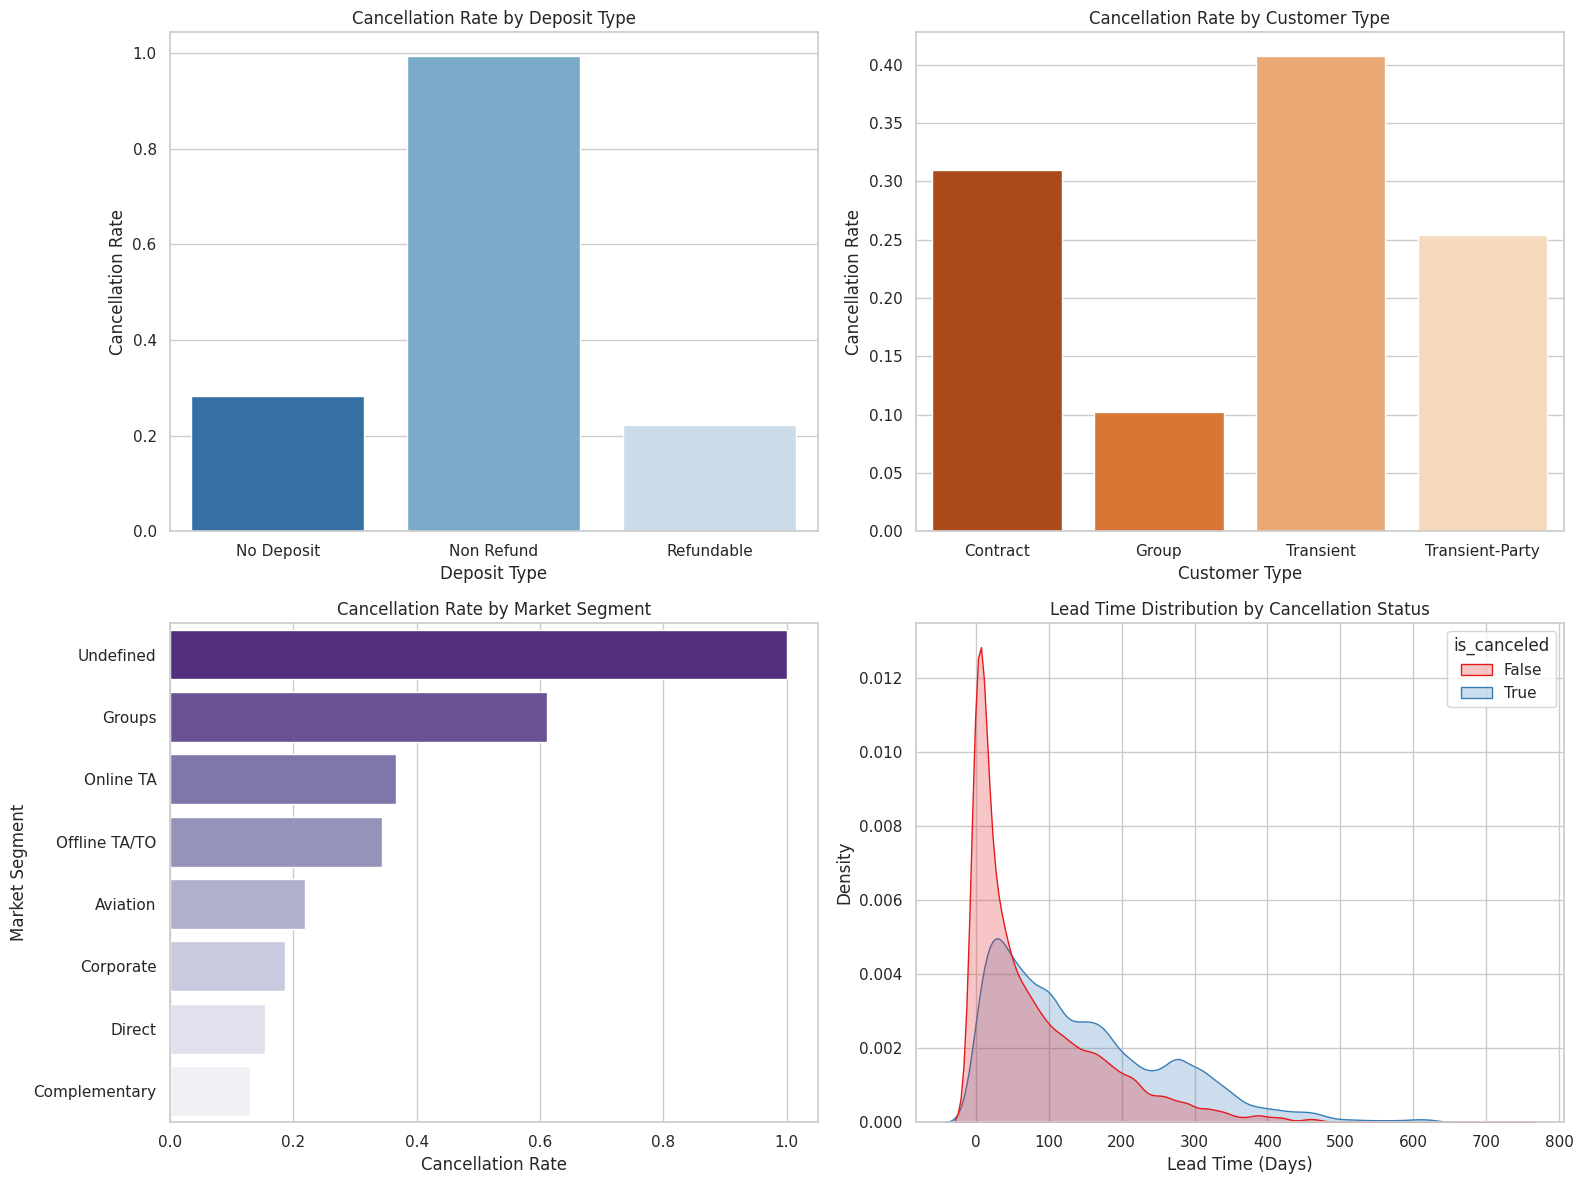

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Merge datasets to bring in descriptive categories
merged_booking = booking.merge(customer, on='Customer_Type_ID', how='left')
merged_booking = merged_booking.merge(market, on='Market_Segment_ID', how='left')
merged_booking = merged_booking.merge(hotel, on='Hotel_ID', how='left')

# Create the missing numeric cancellation column
merged_booking['is_canceled_numeric'] = merged_booking['is_canceled'].astype(int)

# Set plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- Plot 1: Cancellation Rate by Deposit Type ---
deposit_cancel = merged_booking.groupby('deposit_type')['is_canceled_numeric'].mean().reset_index()
sns.barplot(x='deposit_type', y='is_canceled_numeric', data=deposit_cancel, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Cancellation Rate by Deposit Type')
axes[0, 0].set_ylabel('Cancellation Rate')
axes[0, 0].set_xlabel('Deposit Type')

# --- Plot 2: Cancellation Rate by Customer Type ---
customer_cancel = merged_booking.groupby('customer_type')['is_canceled_numeric'].mean().reset_index()
sns.barplot(x='customer_type', y='is_canceled_numeric', data=customer_cancel, ax=axes[0, 1], palette='Oranges_r')
axes[0, 1].set_title('Cancellation Rate by Customer Type')
axes[0, 1].set_ylabel('Cancellation Rate')
axes[0, 1].set_xlabel('Customer Type')

# --- Plot 3: Cancellation Rate by Market Segment ---
market_cancel = merged_booking.groupby('market_segment')['is_canceled_numeric'].mean().sort_values(ascending=False).reset_index()
sns.barplot(x='is_canceled_numeric', y='market_segment', data=market_cancel, ax=axes[1, 0], palette='Purples_r', orient='h')
axes[1, 0].set_title('Cancellation Rate by Market Segment')
axes[1, 0].set_xlabel('Cancellation Rate')
axes[1, 0].set_ylabel('Market Segment')

# --- Plot 4: Lead Time Distribution for Cancelled vs Not Cancelled ---
sns.kdeplot(data=merged_booking, x='lead_time', hue='is_canceled', common_norm=False, shade=True, ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Lead Time Distribution by Cancellation Status')
axes[1, 1].set_xlabel('Lead Time (Days)')
axes[1, 1].set_ylabel('Density')

plt.tight_layout()
plt.show()

### Occupancy Trends: Resort Hotels vs. City Hotels
We will analyze:
1. **Monthly Seasonality**: Average monthly bookings to see peak times for both hotel types.
2. **Stay Duration**: Distribution of total nights stayed.
3. **Booking Patterns**: Lead time comparison between resort and city hotels.

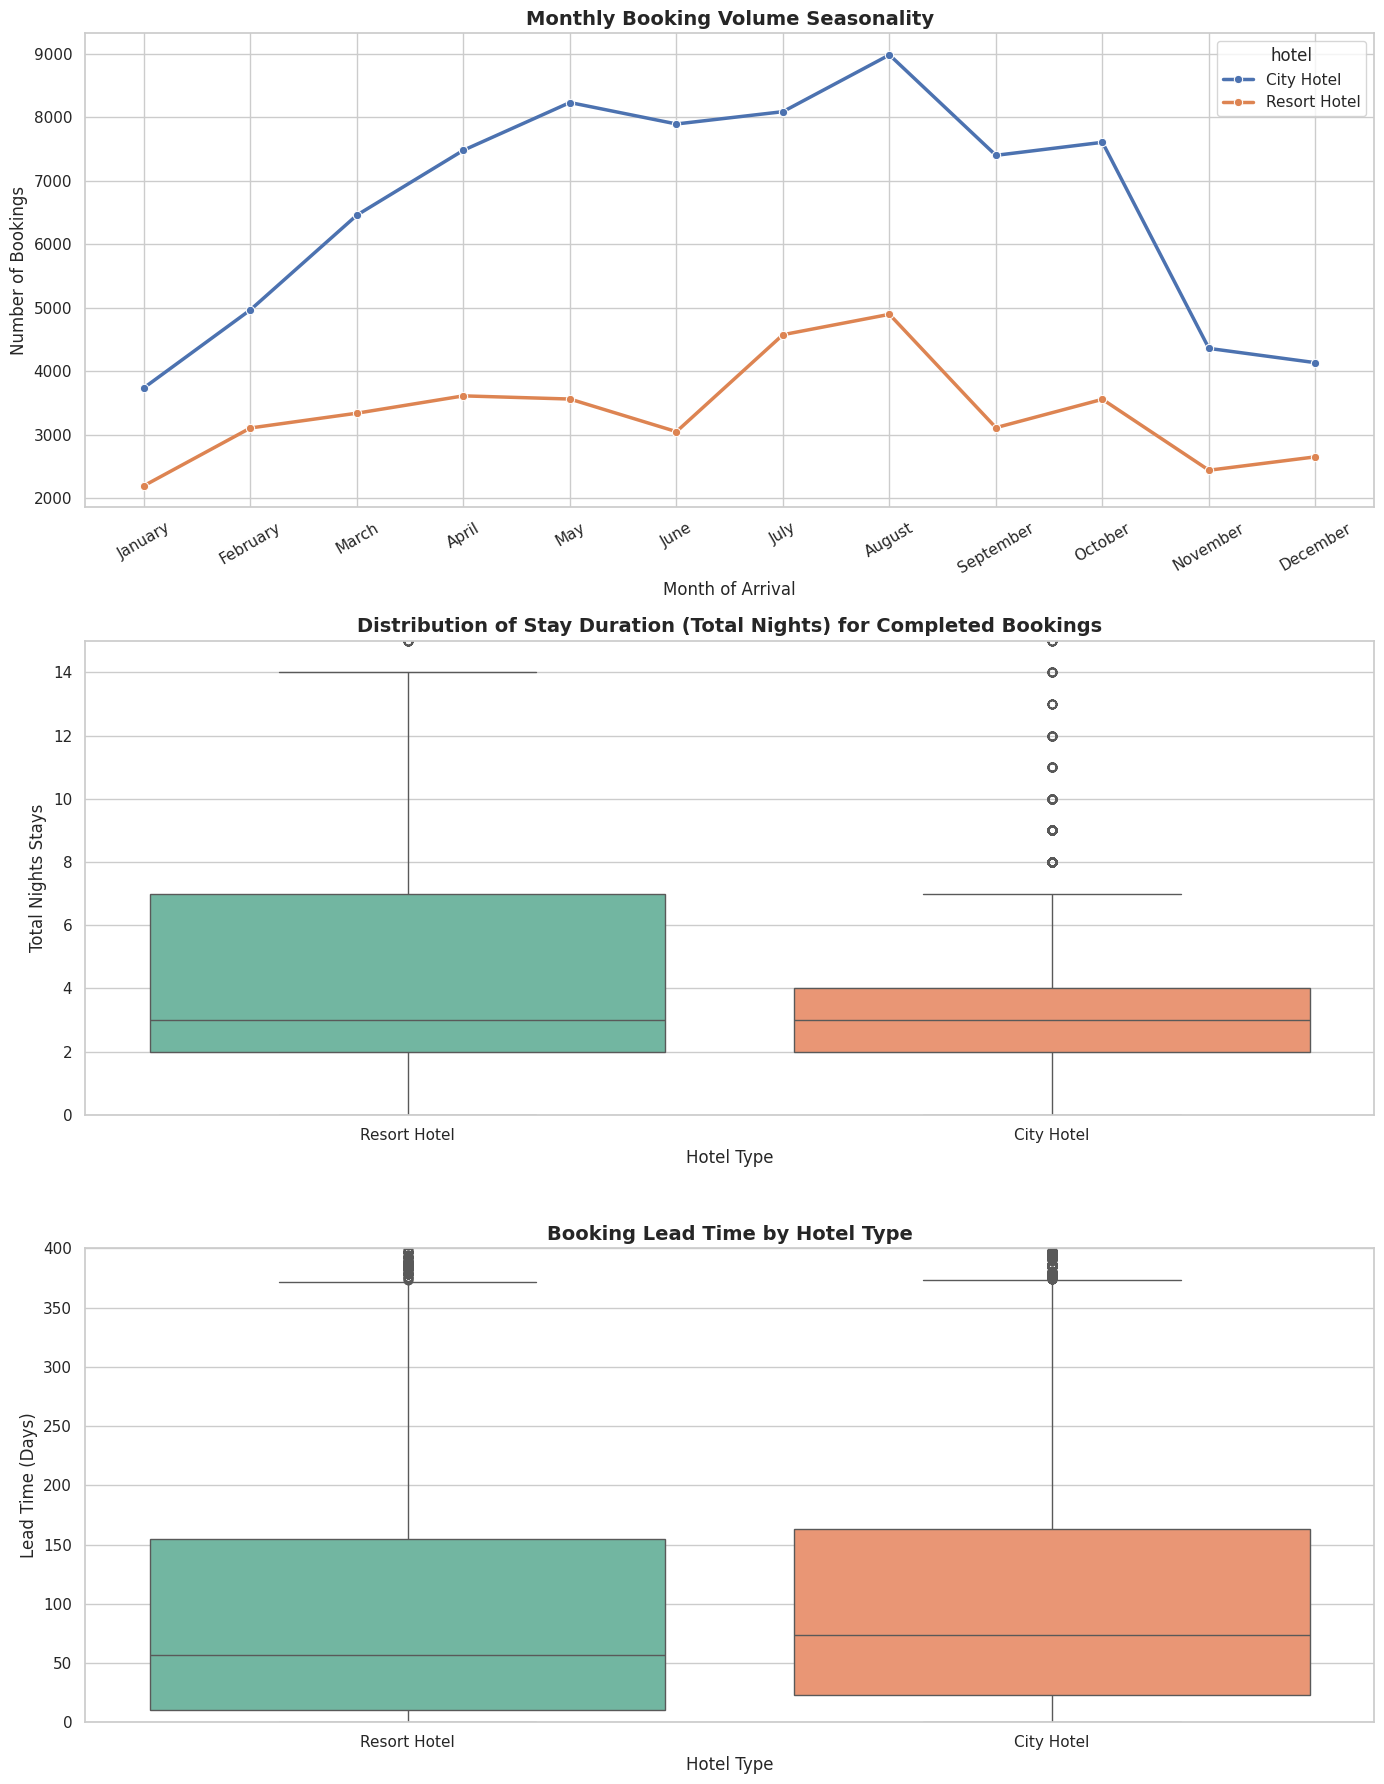

In [28]:
# Ensure hotel descriptions are merged
if 'hotel' not in merged_booking.columns:
    merged_booking = merged_booking.merge(hotel, on='Hotel_ID', how='left')

# Define month ordering for consistent plotting
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

# 1. Monthly Seasonality Trend
monthly_bookings = merged_booking.groupby(['arrival_date_month', 'hotel']).size().reset_index(name='booking_count')
# Filter out potential NaNs or invalid months, and map category for correct chronological ordering
monthly_bookings['arrival_date_month'] = pd.Categorical(monthly_bookings['arrival_date_month'], categories=month_order, ordered=True)
monthly_bookings = monthly_bookings.sort_values('arrival_date_month')

sns.lineplot(data=monthly_bookings, x='arrival_date_month', y='booking_count', hue='hotel', marker='o', linewidth=2.5, ax=axes[0])
axes[0].set_title('Monthly Booking Volume Seasonality', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Month of Arrival')
axes[0].set_ylabel('Number of Bookings')
axes[0].tick_params(axis='x', rotation=30)

# 2. Stay Duration Comparison (Only completed bookings to reflect actual occupancy)
completed_bookings = merged_booking[~merged_booking['is_canceled']]
sns.boxplot(data=completed_bookings, x='hotel', y='total_nights', hue='hotel', ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Distribution of Stay Duration (Total Nights) for Completed Bookings', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hotel Type')
axes[1].set_ylabel('Total Nights Stays')
axes[1].set_ylim(0, 15)  # Restrict y-axis slightly to focus on the main distribution and exclude extreme outliers

# 3. Lead Time booking patterns
sns.boxplot(data=merged_booking, x='hotel', y='lead_time', hue='hotel', ax=axes[2], palette='Set2', legend=False)
axes[2].set_title('Booking Lead Time by Hotel Type', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Hotel Type')
axes[2].set_ylabel('Lead Time (Days)')
axes[2].set_ylim(0, 400) # Focusing on standard lead time ranges

plt.tight_layout()
plt.show()

## Summary Report: Occupancy Trends (Resort vs. City Hotels)

Based on our exploratory visualization of arrival dates, stay duration, and lead times, we have identified several distinct differences in booking patterns between **Resort Hotels** and **City Hotels**:

### 1. Monthly Seasonality (Booking Volumes)
* **City Hotels:** Display a consistently higher booking volume throughout the year. Demand is characterized by a multi-peak trend, with strong surges in **May** and a dramatic annual peak in **August** (~9,000 bookings), followed by a sharp drop in November and December.
* **Resort Hotels:** Experience a steadier, lower overall baseline of bookings that rises steadily during the spring and peaks sharply in **July and August** (~4,500 to 4,900 bookings). This indicates that Resort Hotels are highly seasonal and dependent on the summer holiday window.

### 2. Stay Duration (Total Nights for Completed Bookings)
* **Resort Hotels:** Guests stay significantly longer on average. The median stay duration is around **3 nights**, but the distribution is much broader, with many guests staying between **3 to 7 nights**.
* **City Hotels:** Stays are highly concentrated and shorter. The median stay is **3 nights**, and the interquartile range is tightly bounded between **2 and 4 nights**, reflecting a typical pattern for business travelers or short-weekend city breaks.

### 3. Booking Lead Time Patterns
* **Resort Hotels:** Have a slightly shorter median lead time, though the distribution remains broad. Many resort bookings are made spontaneously or closer to the arrival date during non-peak seasons.
* **City Hotels:** Tend to show a slightly higher median and upper quartile lead time, meaning guests often plan city trips further in advance, or corporate/group blocks lock in rooms ahead of schedule.

In [29]:
# Filter completed bookings specifically for City Hotels
city_completed = completed_bookings[completed_bookings['hotel'] == 'City Hotel']

# Calculate Q1, Q3, and IQR for total_nights
q1 = city_completed['total_nights'].quantile(0.25)
q3 = city_completed['total_nights'].quantile(0.75)
iqr = q3 - q1

# Define Outlier Boundaries
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Identify Outliers
outliers = city_completed[(city_completed['total_nights'] < lower_bound) | (city_completed['total_nights'] > upper_bound)]

print(f"--- Outlier Analysis for City Hotel (Completed Bookings) ---")
print(f"Q1 (25th percentile): {q1} nights")
print(f"Q3 (75th percentile): {q3} nights")
print(f"IQR: {iqr} nights")
print(f"Lower Outlier Boundary: {lower_bound} (any stay less than this is an outlier)")
print(f"Upper Outlier Boundary: {upper_bound} (any stay greater than this is an outlier)")
print(f"\nTotal completed bookings for City Hotel: {len(city_completed)}")
print(f"Number of outlier bookings: {len(outliers)}")
print(f"Percentage of bookings that are outliers: {len(outliers) / len(city_completed) * 100:.2f}%")

print("\nDistribution of these outlier stay durations (Top 10 most common long stays):")
display(outliers['total_nights'].value_counts().head(10))

--- Outlier Analysis for City Hotel (Completed Bookings) ---
Q1 (25th percentile): 2.0 nights
Q3 (75th percentile): 4.0 nights
IQR: 2.0 nights
Lower Outlier Boundary: -1.0 (any stay less than this is an outlier)
Upper Outlier Boundary: 7.0 (any stay greater than this is an outlier)

Total completed bookings for City Hotel: 46228
Number of outlier bookings: 572
Percentage of bookings that are outliers: 1.24%

Distribution of these outlier stay durations (Top 10 most common long stays):


,count
total_nights,
8,209
9,120
10,83
11,36
12,35
14,29
15,16
13,16
16,6


### Distribution Channel Performance Evaluation
We evaluate **Direct**, **Corporate**, **TA/TO**, and **GDS** channels across booking volume, cancellation patterns, and financial contribution.

In [32]:
# Group by distribution channel to aggregate metrics
channel_metrics = merged_booking.groupby('distribution_channel').agg(
    total_bookings=('Booking_ID', 'count'),
    canceled_bookings=('is_canceled', 'sum'),
    # Revenue is only realized for completed (not canceled) bookings
    total_revenue=('total_price', lambda x: x[~merged_booking.loc[x.index, 'is_canceled']].sum())
).reset_index()

# Calculate percentages and rates
total_overall_bookings = channel_metrics['total_bookings'].sum()
total_overall_revenue = channel_metrics['total_revenue'].sum()

channel_metrics['booking_share_%'] = (channel_metrics['total_bookings'] / total_overall_bookings) * 100
channel_metrics['cancellation_rate_%'] = (channel_metrics['canceled_bookings'] / channel_metrics['total_bookings']) * 100
channel_metrics['revenue_share_%'] = (channel_metrics['total_revenue'] / total_overall_revenue) * 100

# Round values for display
channel_metrics['total_revenue'] = channel_metrics['total_revenue'].round(2)
channel_metrics = channel_metrics.round(2)

# Display summary table
print("--- Distribution Channel Performance Table ---")
display(channel_metrics.sort_values(by='total_bookings', ascending=False))


--- Distribution Channel Performance Table ---


,distribution_channel,total_bookings,canceled_bookings,total_revenue,booking_share_%,cancellation_rate_%,revenue_share_%
3,TA/TO,97870,40152,20809562.35,81.98,41.03,80.05
1,Direct,14645,2557,4325241.68,12.27,17.46,16.64
0,Corporate,6677,1474,827884.92,5.59,22.08,3.18
2,GDS,193,37,33007.96,0.16,19.17,0.13
4,Undefined,5,4,563.50,0.00,80.00,0.00


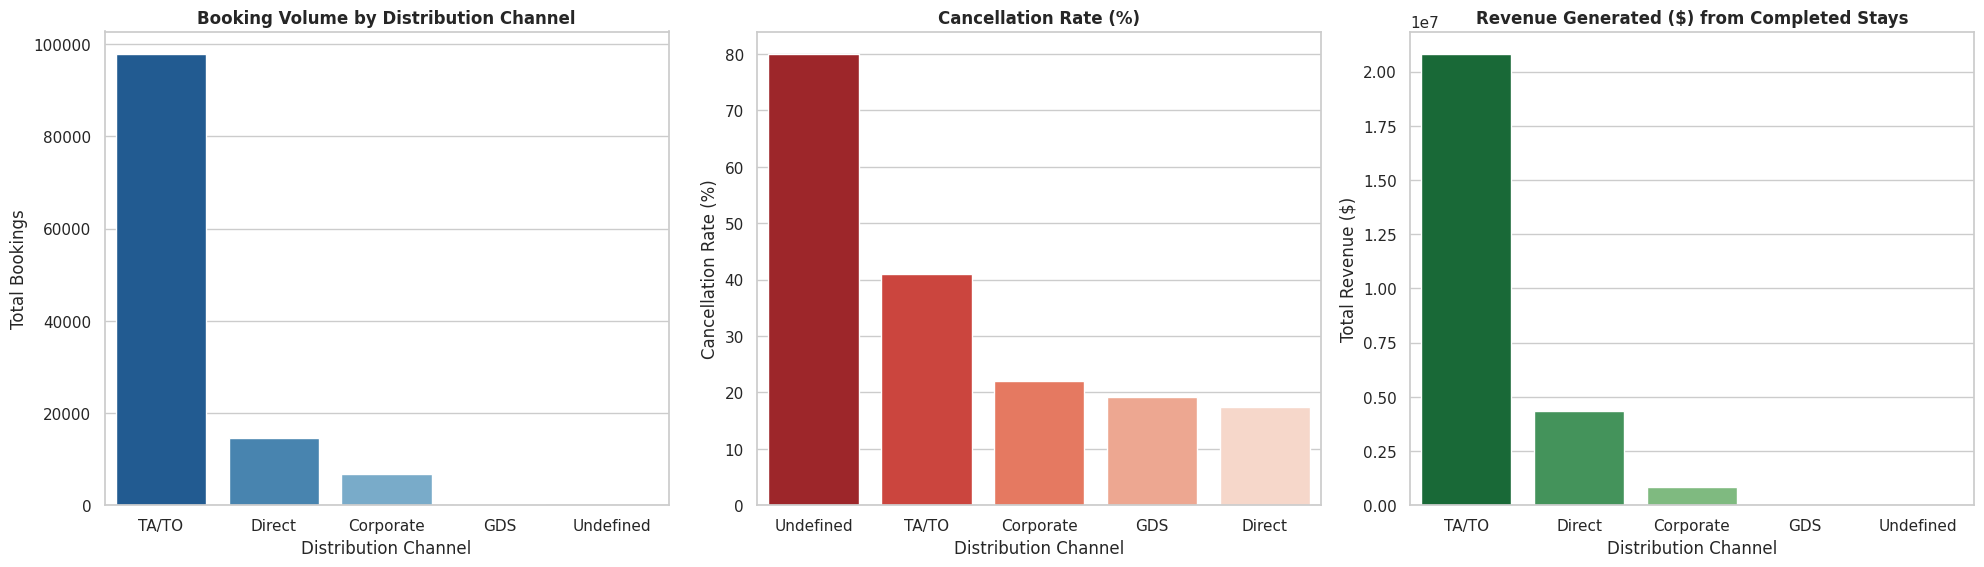

In [31]:
# Visualize the distribution channel metrics
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Booking Volume Share
sns.barplot(data=channel_metrics.sort_values(by='total_bookings', ascending=False),
            x='distribution_channel', y='total_bookings', ax=axes[0], palette='Blues_r', hue='distribution_channel', legend=False)
axes[0].set_title('Booking Volume by Distribution Channel', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Distribution Channel')
axes[0].set_ylabel('Total Bookings')

# 2. Cancellation Rates
sns.barplot(data=channel_metrics.sort_values(by='cancellation_rate_%', ascending=False),
            x='distribution_channel', y='cancellation_rate_%', ax=axes[1], palette='Reds_r', hue='distribution_channel', legend=False)
axes[1].set_title('Cancellation Rate (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Distribution Channel')
axes[1].set_ylabel('Cancellation Rate (%)')

# 3. Revenue Share
sns.barplot(data=channel_metrics.sort_values(by='total_revenue', ascending=False),
            x='distribution_channel', y='total_revenue', ax=axes[2], palette='Greens_r', hue='distribution_channel', legend=False)
axes[2].set_title('Revenue Generated ($) from Completed Stays', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Distribution Channel')
axes[2].set_ylabel('Total Revenue ($)')

plt.tight_layout()
plt.show()

### Reservation Status Analysis (Check-Out, Canceled, No-Show)
We will evaluate key risk factors contributing to cancellations and no-shows to recommend preventive measures.

In [33]:
# 1. Merge reservation status into our master dataframe if not already present
if 'reservation_status' not in merged_booking.columns:
    merged_booking = merged_booking.merge(status, on='Reservation_ID', how='left')

# 2. Overall distribution of reservation statuses
status_distribution = merged_booking['reservation_status'].value_counts().reset_index(name='count')
status_distribution['percentage'] = (status_distribution['count'] / len(merged_booking)) * 100
print("--- Overall Reservation Status Distribution ---")
display(status_distribution)


--- Overall Reservation Status Distribution ---


,reservation_status,count,percentage
0,Check-Out,75166,62.958372
1,Canceled,43017,36.030656
2,No-Show,1207,1.010972


In [34]:
# Analyze Risk Factors
# Risk Factor A: Impact of previous cancellations on future reservation outcome
prev_cancel_impact = merged_booking.groupby('reservation_status')['previous_cancellations'].mean().reset_index()

# Risk Factor B: Impact of repeated guest status
repeated_guest_impact = merged_booking.groupby('is_repeated_guest')['reservation_status'].value_counts(normalize=True).unstack().fillna(0) * 100

# Risk Factor C: Lead Time comparison across reservation statuses
lead_time_stats = merged_booking.groupby('reservation_status')['lead_time'].median().reset_index()

print("\n--- Mean Previous Cancellations by Reservation Status ---")
display(prev_cancel_impact)

print("\n--- Impact of Repeated Guest Status on Outcomes (%) ---")
display(repeated_guest_impact)

print("\n--- Median Lead Time by Reservation Status ---")
display(lead_time_stats)



--- Mean Previous Cancellations by Reservation Status ---


,reservation_status,previous_cancellations
0,Canceled,0.214032
1,Check-Out,0.015792
2,No-Show,0.005800



--- Impact of Repeated Guest Status on Outcomes (%) ---


reservation_status,Canceled,Check-Out,No-Show
is_repeated_guest,,,
False,36.779720,62.214916,1.005364
True,13.307087,85.511811,1.181102



--- Median Lead Time by Reservation Status ---


,reservation_status,lead_time
0,Canceled,116.0
1,Check-Out,45.0
2,No-Show,30.0


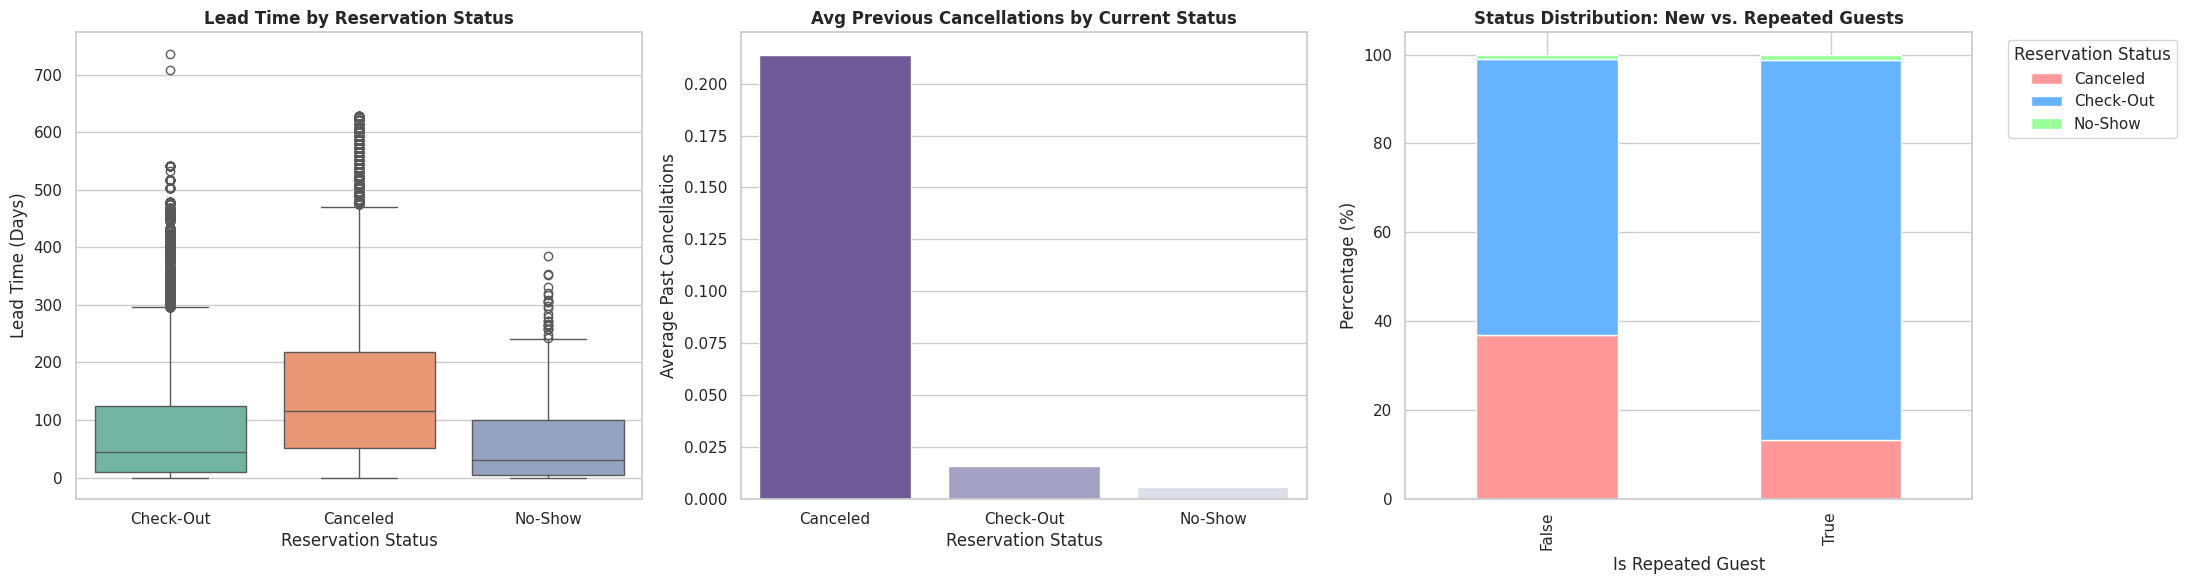

In [35]:
# Visualize reservation status risk factors
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# 1. Lead Time Distribution across Reservation Status
sns.boxplot(data=merged_booking, x='reservation_status', y='lead_time', ax=axes[0], palette='Set2', hue='reservation_status', legend=False)
axes[0].set_title('Lead Time by Reservation Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Reservation Status')
axes[0].set_ylabel('Lead Time (Days)')

# 2. Previous Cancellations rate across status
sns.barplot(data=prev_cancel_impact, x='reservation_status', y='previous_cancellations', ax=axes[1], palette='Purples_r', hue='reservation_status', legend=False)
axes[1].set_title('Avg Previous Cancellations by Current Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Reservation Status')
axes[1].set_ylabel('Average Past Cancellations')

# 3. Repeat Guest behavior
repeated_guest_impact.plot(kind='bar', stacked=True, ax=axes[2], color=['#ff9999','#66b3ff','#99ff99'])
axes[2].set_title('Status Distribution: New vs. Repeated Guests', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Is Repeated Guest')
axes[2].set_ylabel('Percentage (%)')
axes[2].legend(title='Reservation Status', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()